# Problem 4: MNIST Interval Analysis

## 1. Network training and clean accuracy
Train the network for 15 epochs and evaluate it on the MNIST test set.

In [4]:
# MNIST Network Training - 15 epochs
# Converted from the supplied Jupyter notebook for Google Colab.
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
from torchvision import datasets, transforms

use_cuda = torch.cuda.is_available()
device = torch.device('cuda' if use_cuda else 'cpu')
print("Using device:", device)
batch_size = 64
np.random.seed(42)
torch.manual_seed(42)

train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.ToTensor())
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.ToTensor())
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(28 * 28, 200)
        self.fc2 = nn.Linear(200, 10)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        return x  # CrossEntropyLoss expects logits, not softmax probabilities.

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307) / 0.3081

model = nn.Sequential(Normalize(), Net()).to(device)

def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f'Epoch {epoch + 1}/{num_epochs}, Loss: {running_loss / len(train_loader):.3f}')

def test_model(model):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    print(f'Clean accuracy on MNIST test images: {accuracy:.2f}%')
    return accuracy

if __name__ == '__main__':
    train_model(model, 15)
    test_model(model)

Using device: cpu
Epoch 1/15, Loss: 0.593
Epoch 2/15, Loss: 0.297
Epoch 3/15, Loss: 0.248
Epoch 4/15, Loss: 0.215
Epoch 5/15, Loss: 0.190
Epoch 6/15, Loss: 0.170
Epoch 7/15, Loss: 0.155
Epoch 8/15, Loss: 0.142
Epoch 9/15, Loss: 0.130
Epoch 10/15, Loss: 0.121
Epoch 11/15, Loss: 0.113
Epoch 12/15, Loss: 0.106
Epoch 13/15, Loss: 0.099
Epoch 14/15, Loss: 0.093
Epoch 15/15, Loss: 0.088
Clean accuracy on MNIST test images: 97.06%


## 2. Interval analysis and verified accuracy
Evaluate all 10,000 test images for 10 perturbation radii from 0.01 to 0.10 and plot the results.

Interval Analysis Results
-------------------------------------------------------
Epsilon: 0.01 | Verified Accuracy: 63.43% | Verified Images: 6343/10000
Epsilon: 0.02 | Verified Accuracy: 8.47% | Verified Images: 847/10000
Epsilon: 0.03 | Verified Accuracy: 0.74% | Verified Images: 74/10000
Epsilon: 0.04 | Verified Accuracy: 0.04% | Verified Images: 4/10000
Epsilon: 0.05 | Verified Accuracy: 0.00% | Verified Images: 0/10000
Epsilon: 0.06 | Verified Accuracy: 0.00% | Verified Images: 0/10000
Epsilon: 0.07 | Verified Accuracy: 0.00% | Verified Images: 0/10000
Epsilon: 0.08 | Verified Accuracy: 0.00% | Verified Images: 0/10000
Epsilon: 0.09 | Verified Accuracy: 0.00% | Verified Images: 0/10000
Epsilon: 0.10 | Verified Accuracy: 0.00% | Verified Images: 0/10000


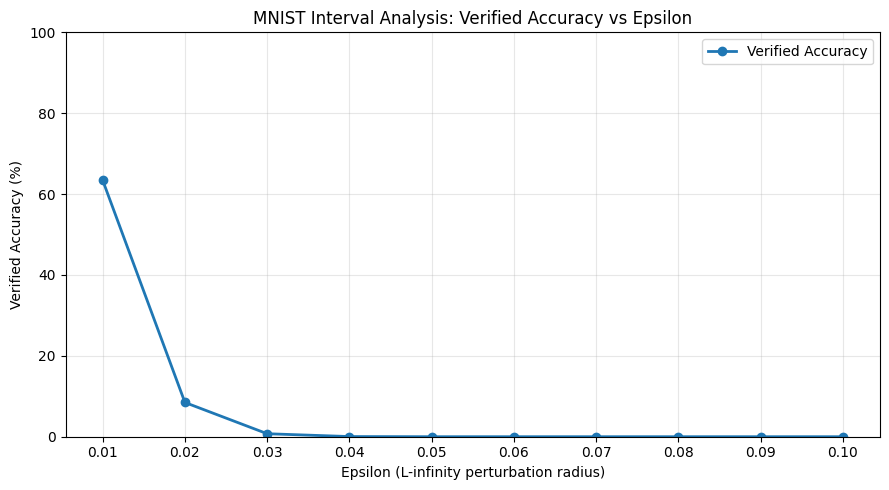

In [6]:

# ============================================================
# INTERVAL ANALYSIS FOR THE MNIST NEURAL NETWORK
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Step 1: Interval propagation through a linear layer
# ------------------------------------------------------------

def linear_bounds(lower, upper, layer):
    W = layer.weight
    b = layer.bias

    W_pos = torch.clamp(W, min=0)
    W_neg = torch.clamp(W, max=0)

    lower_new = (
        F.linear(lower, W_pos, b)
        + F.linear(upper, W_neg)
    )

    upper_new = (
        F.linear(upper, W_pos, b)
        + F.linear(lower, W_neg)
    )

    return lower_new, upper_new


# ------------------------------------------------------------
# Step 2: Propagate input intervals through the network
# ------------------------------------------------------------

def interval_analysis(model, images, labels, epsilon):

    # Create input intervals, keeping pixels between 0 and 1
    lower = torch.clamp(images - epsilon, 0, 1)
    upper = torch.clamp(images + epsilon, 0, 1)

    # Normalize the intervals
    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    # Flatten MNIST images from 28x28 to 784
    lower = lower.flatten(1)
    upper = upper.flatten(1)

    # First fully connected layer: 784 -> 200
    lower, upper = linear_bounds(
        lower, upper, model[1].fc
    )

    # ReLU activation
    lower = F.relu(lower)
    upper = F.relu(upper)

    # --------------------------------------------------------
    # Step 3: Difference output layer
    # Calculate f_y(x') - f_j(x') for every class j != y
    # --------------------------------------------------------

    W = model[1].fc2.weight
    b = model[1].fc2.bias

    # One difference matrix for each image in the batch
    W_diff = W[labels].unsqueeze(1) - W.unsqueeze(0)
    b_diff = b[labels].unsqueeze(1) - b.unsqueeze(0)

    W_pos = torch.clamp(W_diff, min=0)
    W_neg = torch.clamp(W_diff, max=0)

    # Lower bounds of all class differences
    diff_lower = (
        torch.bmm(W_pos, lower.unsqueeze(2)).squeeze(2)
        + torch.bmm(W_neg, upper.unsqueeze(2)).squeeze(2)
        + b_diff
    )

    # Ignore the comparison of the true class with itself
    diff_lower.scatter_(
        1, labels.unsqueeze(1), float("inf")
    )

    # Certified if every competing class has a nonnegative lower margin
    verified = (diff_lower >= 0).all(dim=1)

    return verified


# ------------------------------------------------------------
# Step 4: Evaluate the entire MNIST test dataset
# ------------------------------------------------------------

def evaluate_verified_accuracy(model, test_loader, epsilon):

    model.eval()

    verified_count = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            verified = interval_analysis(
                model, images, labels, epsilon
            )

            verified_count += verified.sum().item()
            total += labels.size(0)

    accuracy = 100 * verified_count / total

    return accuracy, verified_count


# ------------------------------------------------------------
# Step 5: Test 10 epsilon values from 0.01 to 0.10
# ------------------------------------------------------------

epsilon_values = np.linspace(0.01, 0.10, 10)

verified_accuracies = []
verified_counts = []

print("Interval Analysis Results")
print("-" * 55)

for epsilon in epsilon_values:

    accuracy, count = evaluate_verified_accuracy(
        model, test_loader, float(epsilon)
    )

    verified_accuracies.append(accuracy)
    verified_counts.append(count)

    print(
        f"Epsilon: {epsilon:.2f} | "
        f"Verified Accuracy: {accuracy:.2f}% | "
        f"Verified Images: {count}/10000"
    )


# ------------------------------------------------------------
# Step 6: Plot verified accuracy against epsilon
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epsilon_values,
    verified_accuracies,
    marker="o",
    linewidth=2,
    label="Verified Accuracy"
)

plt.xlabel("Epsilon (L-infinity perturbation radius)")
plt.ylabel("Verified Accuracy (%)")
plt.title("MNIST Interval Analysis: Verified Accuracy vs Epsilon")

plt.xticks(epsilon_values)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


## 3. Observations

I trained the model for 15 epochs. The clean accuracy was **97.06%** on the 10,000 test images. This means the model got most of the original images right.

When epsilon got larger, the verified accuracy went down. At epsilon 0.01, it was **63.43%**. At 0.02, it dropped to **8.47%**. At 0.03 and 0.04, it was only **0.74%** and **0.04%**. From 0.05 to 0.10, it was **0%**.

A larger epsilon means each pixel can change more. The code has to check a larger range of possible images. The bounds also get wider, so it is harder to prove that the model will give the correct answer for all allowed changes.

The model did well on the original images, but the verified accuracy was much lower. This shows that getting an original image right does not mean we can prove that the model will still get it right after the pixels change.

A result of 0% does not mean every image can be changed to make the model give a wrong answer. It means interval analysis could not prove that any of the test images were robust at that epsilon. The bounds may be too wide to prove it.
